# YAGO 4.5 KGE — notes and embedding visualizations

This notebook documents the `yago45-kge` example and visualizes the trained
**200-dimensional** entity/relation embeddings:

- **Data**: YAGO 4.5 Turtle → entity–entity triples (literals/labels dropped) →
  GestaltDB (RocksDB) ingest → CSR `SamplerSnapshot`.
- **Model**: trainable entity `[N,200]` + relation `[R,200]` tables → masked
  2-step `tf_gnns.GraphNetMPNN_MLP` encoder → ComplEx scorer, plus a shallow
  ComplEx objective directly supervising the exported base tables.
- **Training**: compiled `@tf.function` step; `tf.data` feed from array-backed CSR
  (no KV reads in the hot path).
- **Runs**: `data/yago45` (tiny: 352k triples / 300k entities / 57 relations)
  and `data/yago45_facts` (12.0M train triples / 4.18M entities / 25 relations,
  final published run: 150k steps). Set `USE_FACTS = True` below to visualize the facts run
  (needs ~4 GB RAM for the entity matrix).


In [1]:
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import polars as pl

USE_FACTS = os.environ.get("YAGO_USE_FACTS", "") == "1"  # set YAGO_USE_FACTS=1 for the 4.2M-entity run

# Works both in the workspace layout (data at repo root) and in a
# self-contained example checkout (data inside the example dir).
here = Path.cwd()
def _example_root(start):
    for p in [start, *start.parents]:
        if (p / "yago").exists() and (p / "scripts").exists():
            return p
    return start
ex = _example_root(here)
name = "yago45_facts" if USE_FACTS else "yago45"
cands = [(ex / ".." / "data" / name).resolve(), ex / "data" / name]
DATA_ROOT = next(p for p in cands if p.exists())
ART = DATA_ROOT / "artifacts"
RUN_ART = Path(os.environ.get("YAGO_RUN_ARTIFACTS", ART))
print("DATA_ROOT:", DATA_ROOT, "RUN_ART:", RUN_ART)

DATA_ROOT: /home/charilaos/Workspace/gestalt-example/data/yago45_facts RUN_ART: /home/charilaos/Workspace/gestalt-example/data/yago45_facts/runs/masked-optuna-best-20k


In [2]:
import json
meta = json.loads((ART / "metadata.json").read_text())
print(f"nodes={meta['num_nodes']:,} edges={meta['num_edges']:,} relations={meta['num_relations']}")
node_map = pl.read_parquet(ART / "node_map.parquet").sort("node_int")
rel_map = pl.read_parquet(ART / "relation_map.parquet").sort("rel_int")
print(node_map.head(3))
print(rel_map)

nodes=4,181,515 edges=11,987,137 relations=25
shape: (3, 3)
┌──────────┬─────────────────────────────────┬────────┐
│ node_int ┆ node_id                         ┆ kind   │
│ ---      ┆ ---                             ┆ ---    │
│ u32      ┆ str                             ┆ str    │
╞══════════╪═════════════════════════════════╪════════╡
│ 0        ┆ yago:Second_Honeymoon__u0028_n… ┆ Entity │
│ 1        ┆ yago:Abington_Congregational_C… ┆ Entity │
│ 2        ┆ yago:Nobela                     ┆ Entity │
└──────────┴─────────────────────────────────┴────────┘
shape: (25, 3)
┌─────────┬───────────────────┬────────┐
│ rel_int ┆ edge_type         ┆ len    │
│ ---     ┆ ---               ┆ ---    │
│ u32     ┆ str               ┆ u32    │
╞═════════╪═══════════════════╪════════╡
│ 0       ┆ rdf:type          ┆ 998841 │
│ 1       ┆ schema:actor      ┆ 743804 │
│ 2       ┆ schema:alumniOf   ┆ 909793 │
│ 3       ┆ schema:author     ┆ 105631 │
│ 4       ┆ schema:award      ┆ 415083 │
│ …       ┆

## Relation distribution

Stratified sampling downstream relies on this skew (tiny is taxonomy-heavy;
facts is capped at 500k/relation for diversity).

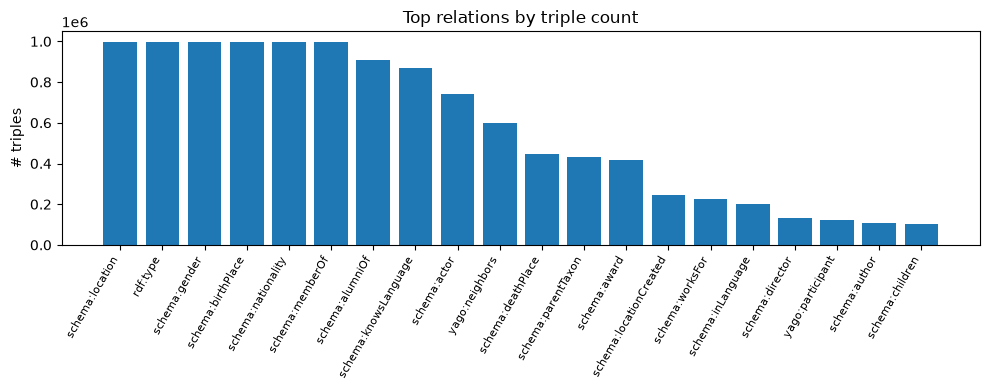

In [3]:
import matplotlib.pyplot as plt
top = rel_map.sort("len", descending=True).head(20)
names = top["edge_type"].to_list(); counts = top["len"].to_list()
plt.figure(figsize=(10, 4))
plt.bar(range(len(names)), counts)
plt.xticks(range(len(names)), names, rotation=60, ha="right", fontsize=8)
plt.ylabel("# triples"); plt.title("Top relations by triple count")
plt.tight_layout(); plt.show()

## Embedding stats and stratified subset

We sample entities stratified by their *dominant incident relation* so the
t-SNE plot tests whether the contrastive objective separated relational roles.


entity (4181515, 200) relation (25, 200)


finite: True True


entity norm: mean=0.712 std=0.162


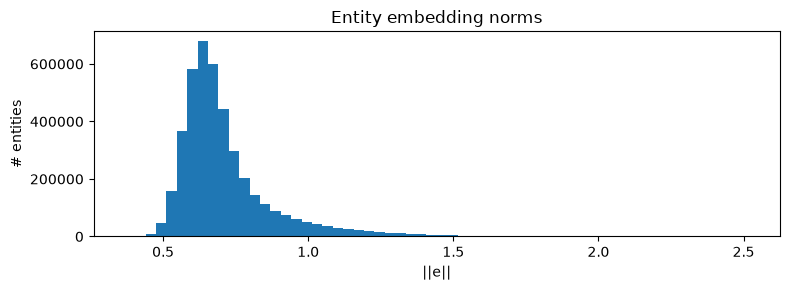

In [4]:
data = np.load(RUN_ART / "yago45_embeddings_200d.npz")
E = data["entity_base_200d" if "entity_base_200d" in data else "entity"].astype(np.float32)
R = data["relation_base_200d" if "relation_base_200d" in data else "relation"].astype(np.float32)
ids = data["node_ids"].tolist()
relation_ids = data["relation_ids"].tolist()
print("entity", E.shape, "relation", R.shape)
assert E.shape[1] == 200 and R.shape[1] == 200
print("finite:", np.isfinite(E).all(), np.isfinite(R).all())
norms = np.linalg.norm(E, axis=1)
print(f"entity norm: mean={norms.mean():.3f} std={norms.std():.3f}")
plt.figure(figsize=(8, 3))
plt.hist(norms, bins=60); plt.xlabel("||e||"); plt.ylabel("# entities")
plt.title("Entity embedding norms"); plt.tight_layout(); plt.show()

In [5]:
triples = pl.scan_parquet(ART / "triples_train.parquet")
edom = (triples.group_by(["source", "edge_type"]).len()
        .sort(["source", "len"], descending=[False, True])
        .group_by("source").first()
        .collect())
print(f"entities with dominant relation: {len(edom):,}")
TOP_RELS = rel_map.sort("len", descending=True).head(8)["edge_type"].to_list()
print("plot relations:", TOP_RELS)
rng = np.random.default_rng(0)
PER_REL, sel_idx, sel_lab = 500, [], []
id_to_row = {nid: r for r, nid in enumerate(ids)}
for rel in TOP_RELS:
    cand = edom.filter(pl.col("edge_type") == rel)["source"].to_list()
    cand = [c for c in cand if c in id_to_row]
    take = rng.choice(cand, size=min(PER_REL, len(cand)), replace=False)
    sel_idx += [id_to_row[c] for c in take]; sel_lab += [rel] * len(take)
sel_idx = np.array(sel_idx); print("subset:", len(sel_idx))

entities with dominant relation: 4,032,455
plot relations: ['schema:location', 'rdf:type', 'schema:gender', 'schema:birthPlace', 'schema:nationality', 'schema:memberOf', 'schema:alumniOf', 'schema:knowsLanguage']


subset: 4000


## t-SNE of the entity subset, colored by dominant relation

t-SNE done: (4000, 2)


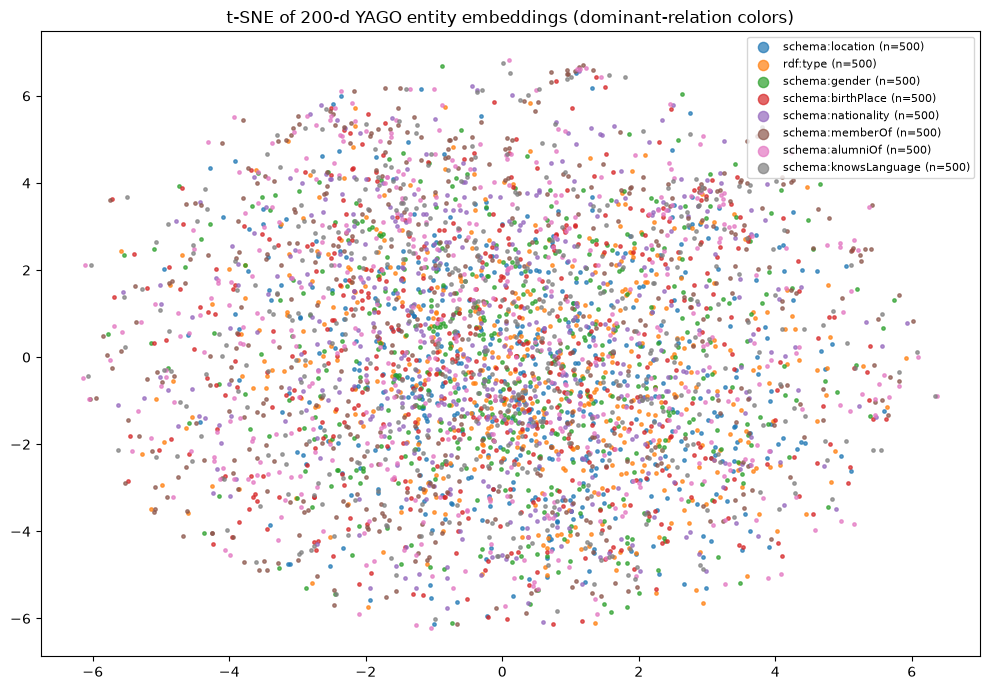

saved /home/charilaos/Workspace/gestalt-example/data/yago45_facts/artifacts/tsne_subset.png


In [6]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
Xs = StandardScaler().fit_transform(E[sel_idx])
Z = TSNE(n_components=2, perplexity=30, max_iter=1000,
         learning_rate="auto", init="pca", random_state=0).fit_transform(Xs)
print("t-SNE done:", Z.shape)
plt.figure(figsize=(10, 7))
for rel in TOP_RELS:
    m = np.array(sel_lab) == rel
    if m.sum():
        plt.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.7, label=f"{rel} (n={m.sum()})")
plt.legend(markerscale=3, fontsize=8, loc="best")
plt.title("t-SNE of 200-d YAGO entity embeddings (dominant-relation colors)")
plt.tight_layout()
out = ART / "tsne_subset.png"; plt.savefig(out, dpi=120); plt.show()
print("saved", out)

## Train / validation curves (held-out triples)

Logged every `eval_every` steps during training. Base-table ComplEx scores on
the held-out split (never in the sampler snapshot): sampled ranking over
1 positive + 50 random negatives. This is not full-candidate MRR. If `curves.jsonl` is missing, the run
predates validation logging.


shape: (3, 5)
┌───────┬────────────┬───────────┬──────────────┬─────────────┐
│ step  ┆ train_loss ┆ valid_mrr ┆ valid_hits10 ┆ valid_hits1 │
│ ---   ┆ ---        ┆ ---       ┆ ---          ┆ ---         │
│ i64   ┆ f64        ┆ f64       ┆ f64          ┆ f64         │
╞═══════╪════════════╪═══════════╪══════════════╪═════════════╡
│ 18000 ┆ 9.921443   ┆ 0.269922  ┆ 0.397        ┆ 0.192       │
│ 19000 ┆ 9.907825   ┆ 0.274296  ┆ 0.4045       ┆ 0.197       │
│ 20000 ┆ 9.801181   ┆ 0.272318  ┆ 0.3945       ┆ 0.1955      │
└───────┴────────────┴───────────┴──────────────┴─────────────┘
best valid MRR=0.2743 at step 19000


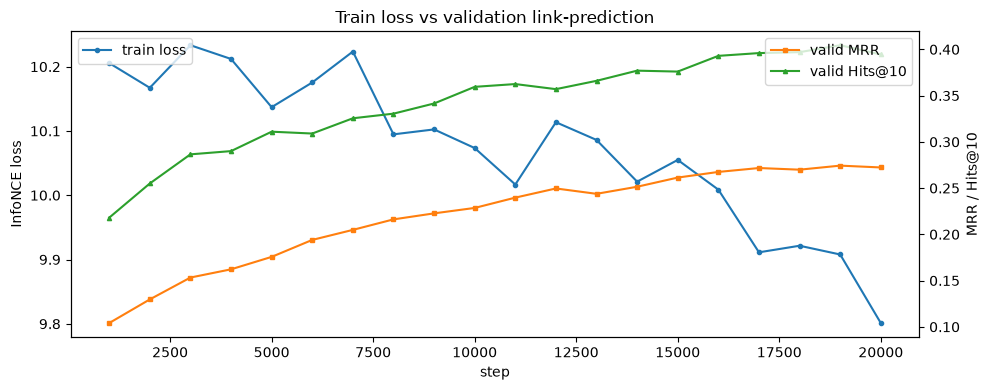

In [7]:
import json as _json
curves_file = RUN_ART / "curves.jsonl"
if curves_file.exists():
    curves = [_json.loads(l) for l in curves_file.read_text().splitlines()]
    cdf = pl.DataFrame(curves)
    print(cdf.tail(3))
    bi = int(cdf["valid_mrr"].to_numpy().argmax())
    print(f"best valid MRR={cdf['valid_mrr'][bi]:.4f} at step {int(cdf['step'][bi])}")
    fig, ax1 = plt.subplots(figsize=(10, 4))
    ax1.plot(cdf["step"].to_numpy(), cdf["train_loss"].to_numpy(), "o-", ms=3, label="train loss")
    ax1.set_xlabel("step"); ax1.set_ylabel("InfoNCE loss"); ax1.legend(loc="upper left")
    ax2 = ax1.twinx()
    ax2.plot(cdf["step"].to_numpy(), cdf["valid_mrr"].to_numpy(), "s-", ms=3, color="C1", label="valid MRR")
    ax2.plot(cdf["step"].to_numpy(), cdf["valid_hits10"].to_numpy(), "^-", ms=3, color="C2", label="valid Hits@10")
    ax2.set_ylabel("MRR / Hits@10"); ax2.legend(loc="upper right")
    plt.title("Train loss vs validation link-prediction"); plt.tight_layout(); plt.show()
else:
    print("no curves.jsonl (run predates validation logging)")

## Negative-sampler control

A seeded 50-step comparison uses the same masked GNN recipe for both samplers.
It is a throughput check, not a converged-quality comparison.


shape: (2, 5)
┌─────────┬───────┬────────────────┬─────────────────┬──────────────────┐
│ sampler ┆ steps ┆ best_valid_mrr ┆ final_valid_mrr ┆ training_seconds │
│ ---     ┆ ---   ┆ ---            ┆ ---             ┆ ---              │
│ str     ┆ i64   ┆ f64            ┆ f64             ┆ f64              │
╞═════════╪═══════╪════════════════╪═════════════════╪══════════════════╡
│ engine  ┆ 50    ┆ 0.081619       ┆ 0.081548        ┆ 379.617324       │
│ hybrid  ┆ 50    ┆ 0.083887       ┆ 0.083887        ┆ 9.282116         │
└─────────┴───────┴────────────────┴─────────────────┴──────────────────┘


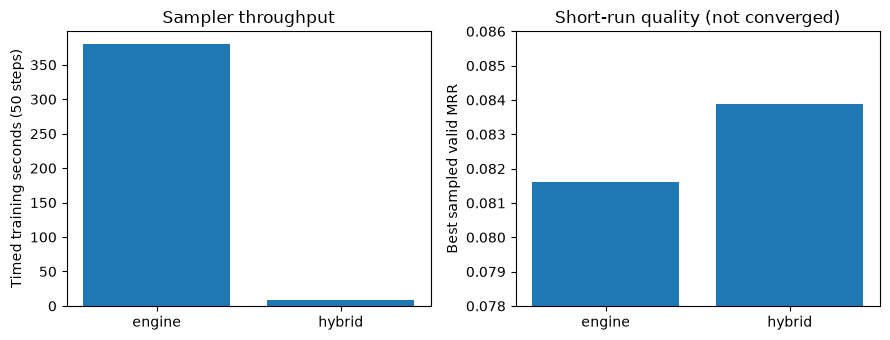

In [8]:
control_file = ex / "experiments" / "masked_negative_control.csv"
if control_file.exists():
    control = pl.read_csv(control_file)
    print(control)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    axes[0].bar(control["sampler"], control["training_seconds"])
    axes[0].set_ylabel("Timed training seconds (50 steps)"); axes[0].set_title("Sampler throughput")
    axes[1].bar(control["sampler"], control["best_valid_mrr"])
    axes[1].set_ylabel("Best sampled valid MRR"); axes[1].set_ylim(.078, .086)
    axes[1].set_title("Short-run quality (not converged)")
    plt.tight_layout(); plt.show()
else:
    print("control CSV not present")

### Optuna hybrid tuning

Four 1,000-step masked trials tune learning rate, batch size, negative count,
self-adversarial temperature, and shallow auxiliary weight. The SQLite study,
per-trial logs, summaries, and curves remain local; the compact CSV is published.


shape: (4, 8)
┌────────┬──────────┬─────────────┬────────────┬────────────┬────────────┬────────────┬────────────┐
│ number ┆ value    ┆ param_learn ┆ param_batc ┆ param_nega ┆ param_adv_ ┆ param_aux_ ┆ attr_elaps │
│ ---    ┆ ---      ┆ ing_rate    ┆ h_size     ┆ tives      ┆ temp       ┆ weight     ┆ ed_seconds │
│ i64    ┆ f64      ┆ ---         ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---        │
│        ┆          ┆ f64         ┆ i64        ┆ i64        ┆ f64        ┆ f64        ┆ f64        │
╞════════╪══════════╪═════════════╪════════════╪════════════╪════════════╪════════════╪════════════╡
│ 0      ┆ 0.102499 ┆ 0.000504    ┆ 128        ┆ 16         ┆ 1.413564   ┆ 1.003268   ┆ 131.905971 │
│ 1      ┆ 0.091085 ┆ 0.00038     ┆ 64         ┆ 32         ┆ 1.059281   ┆ 0.84521    ┆ 125.186328 │
│ 2      ┆ 0.087442 ┆ 0.00017     ┆ 64         ┆ 16         ┆ 0.979087   ┆ 1.294511   ┆ 124.366715 │
│ 3      ┆ 0.082599 ┆ 0.000107    ┆ 128        ┆ 8          ┆ 1.719262   ┆ 0.

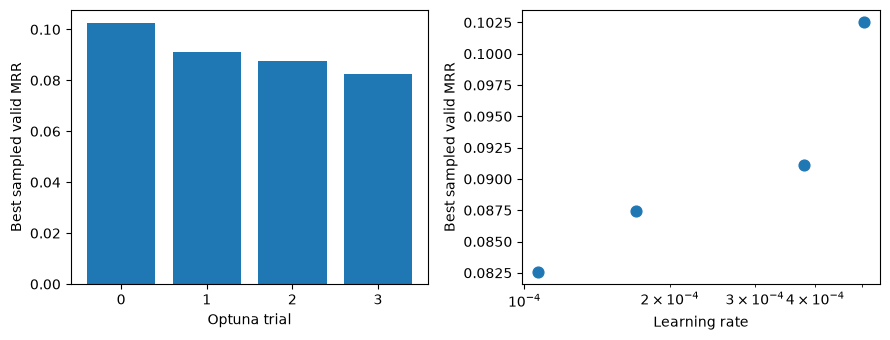

In [9]:
tuning_file = ex / "experiments" / "optuna_masked_hybrid_1k.csv"
if tuning_file.exists():
    tuning = pl.read_csv(tuning_file)
    print(tuning.sort("value", descending=True))
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    axes[0].bar(tuning["number"].cast(pl.String), tuning["value"])
    axes[0].set_xlabel("Optuna trial"); axes[0].set_ylabel("Best sampled valid MRR")
    axes[1].scatter(tuning["param_learning_rate"], tuning["value"], s=60)
    axes[1].set_xscale("log"); axes[1].set_xlabel("Learning rate")
    axes[1].set_ylabel("Best sampled valid MRR")
    plt.tight_layout(); plt.show()
else:
    print("tuning CSV not present")

### Fixed-budget model ablation

The true shallow path scores the exported 200-d tables directly with global
corruptions. All variants use the same split, seed, optimizer recipe and 1,000
updates. Validation measures the exported base tables.


shape: (3, 5)
┌────────────────────────┬───────┬───────────┬─────────────┬──────────────┐
│ model                  ┆ steps ┆ valid_mrr ┆ valid_hits1 ┆ valid_hits10 │
│ ---                    ┆ ---   ┆ ---       ┆ ---         ┆ ---          │
│ str                    ┆ i64   ┆ f64       ┆ f64         ┆ f64          │
╞════════════════════════╪═══════╪═══════════╪═════════════╪══════════════╡
│ shallow ComplEx        ┆ 1000  ┆ 0.102495  ┆ 0.034       ┆ 0.2095       │
│ masked GNN only        ┆ 1000  ┆ 0.094135  ┆ 0.023       ┆ 0.208        │
│ masked GNN + auxiliary ┆ 1000  ┆ 0.104063  ┆ 0.034       ┆ 0.218        │
└────────────────────────┴───────┴───────────┴─────────────┴──────────────┘


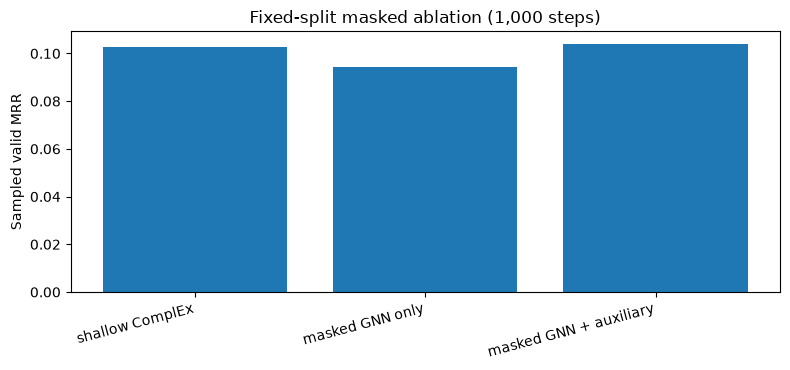

In [10]:
ablation_file = ex / "experiments" / "masked_model_ablation_1k.csv"
if ablation_file.exists():
    ablation = pl.read_csv(ablation_file)
    print(ablation)
    plt.figure(figsize=(8, 3.8))
    plt.bar(ablation["model"], ablation["valid_mrr"])
    plt.xticks(rotation=15, ha="right"); plt.ylabel("Sampled valid MRR")
    plt.title("Fixed-split masked ablation (1,000 steps)")
    plt.tight_layout(); plt.show()
else:
    print("ablation CSV not present")

## Class-conditioned t-SNE (the right lens for ComplEx)

ComplEx geometry is per-relation (bilinear), so raw t-SNE colored by a crude
"dominant relation" proxy looks mixed even for good embeddings. Coloring by
the *true object of one relation* (gender, nationality) reveals the learned
class structure. If these plots show clean clusters, the model separated the
classes; ranking metrics (MRR/Hits) quantify it globally.


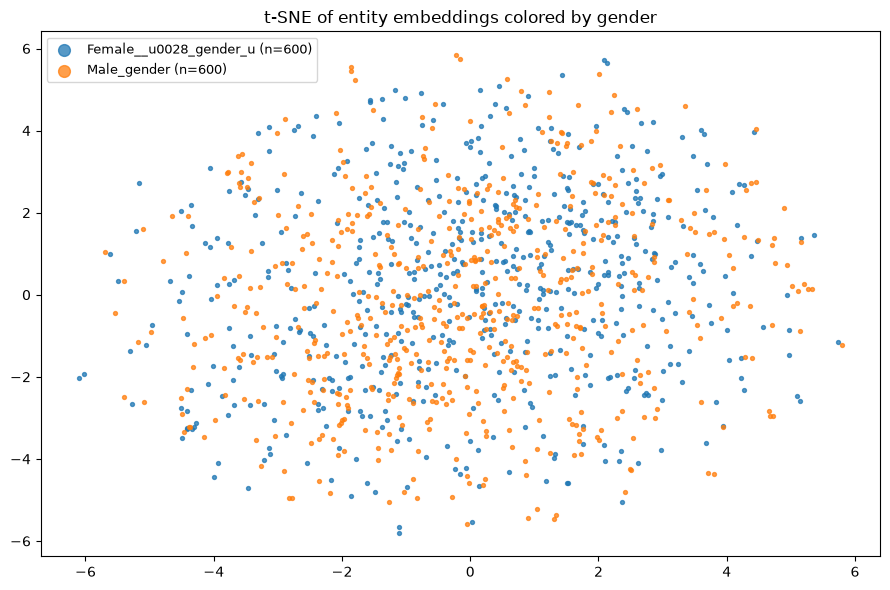

saved /home/charilaos/Workspace/gestalt-example/data/yago45_facts/artifacts/tsne_gender.png


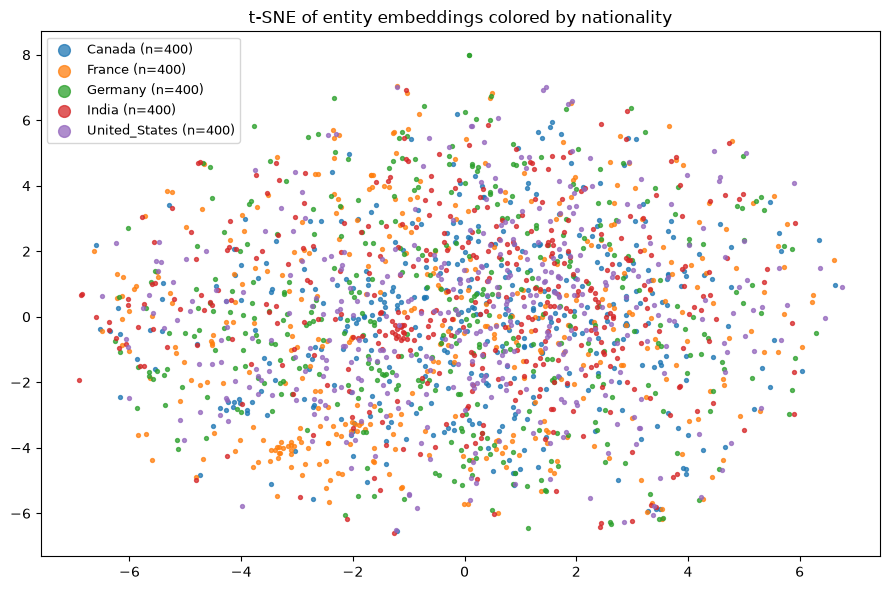

saved /home/charilaos/Workspace/gestalt-example/data/yago45_facts/artifacts/tsne_nationality.png


In [11]:
_KEEP = {
    "schema:gender": ["yago:Male_gender", "yago:Female__u0028_gender_u0029_"],
    "schema:nationality": ["yago:United_States", "yago:France", "yago:Canada", "yago:Germany", "yago:India"],
}
for _rel, _objs in _KEEP.items():
    _df = triples.filter(pl.col("edge_type") == _rel).select(["source", "target"]).collect()
    _df = _df.filter(pl.col("target").is_in(_objs))
    _rows, _labs = [], []
    for _o in _objs:
        _c = [s for s in _df.filter(pl.col("target") == _o)["source"].to_list() if s in id_to_row]
        if not _c:
            continue
        _take = list(rng.choice(_c, size=min(600 if len(_objs) <= 2 else 400, len(_c)), replace=False))
        _rows += _take; _labs += [_o.split(":")[-1][:22]] * len(_take)
    _X = StandardScaler().fit_transform(E[[id_to_row[s] for s in _rows]])
    _Z = TSNE(n_components=2, perplexity=30, max_iter=1000,
              learning_rate="auto", init="pca", random_state=0).fit_transform(_X)
    plt.figure(figsize=(9, 6))
    for _lab in sorted(set(_labs)):
        _m = np.array(_labs) == _lab
        plt.scatter(_Z[_m, 0], _Z[_m, 1], s=8, alpha=0.75, label=f"{_lab} (n={_m.sum()})")
    plt.legend(markerscale=3, fontsize=9)
    plt.title(f"t-SNE of entity embeddings colored by {_rel.split(':')[-1]}")
    plt.tight_layout()
    _fn = ART / f"tsne_{_rel.split(':')[-1]}.png"
    plt.savefig(_fn, dpi=120); plt.show()
    print("saved", _fn)

## Relation–relation cosine structure

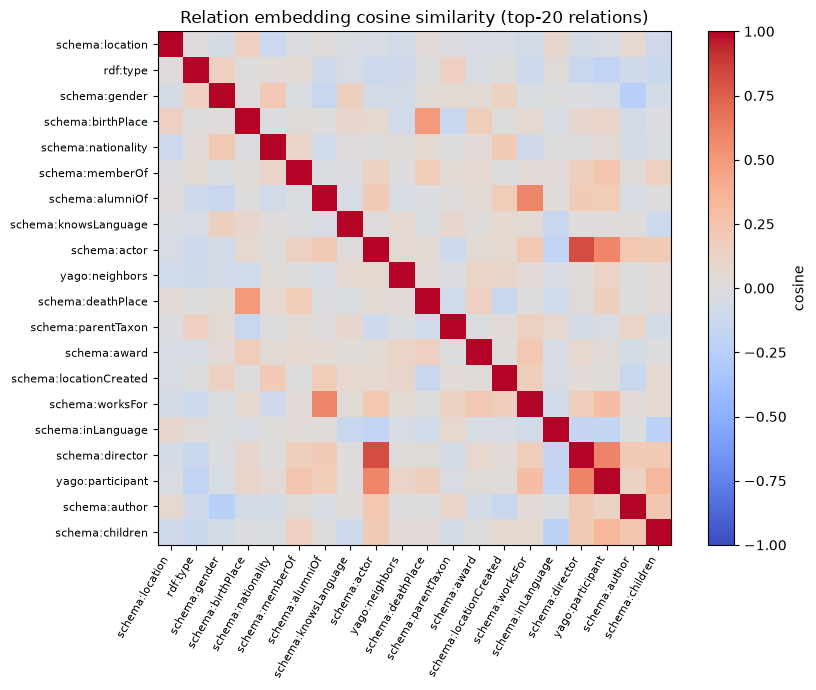

In [12]:
Rn = R / (np.linalg.norm(R, axis=1, keepdims=True) + 1e-9)
S = Rn @ Rn.T
order = np.argsort(-rel_map["len"].to_numpy())[:20]
labels = [rel_map["edge_type"][int(i)] for i in order]
plt.figure(figsize=(9, 7))
plt.imshow(S[np.ix_(order, order)], vmin=-1, vmax=1, cmap="coolwarm")
plt.xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8)
plt.yticks(range(len(labels)), labels, fontsize=8)
plt.title("Relation embedding cosine similarity (top-20 relations)")
plt.colorbar(label="cosine"); plt.tight_layout(); plt.show()

## Relation-conditioned retrieval (the primary KGE query)

Knowledge-graph embeddings answer **(subject, relation, ?)**. The following
uses the trained ComplEx function and candidates observed in that relation's
object range. It is the
correct counterpart to training; generic entity-to-entity cosine is not.

These are the first matching held-out rows, not cherry-picked successes. Mixed
ranks are expected at 20k steps; aggregate sampled-filtered metrics are the
quality measure, while these rows make failures inspectable.


In [13]:
id_to_row = {v: i for i, v in enumerate(ids)}
rel_to_row = {v: i for i, v in enumerate(relation_ids)}

def complex_object_scores(subject, relation, candidates):
    s, r = E[subject], R[relation]
    d = E.shape[1] // 2
    sr, si = s[:d], s[d:]; rr, ri = r[:d], r[d:]
    o = E[np.asarray(candidates)]; ore, oim = o[:, :d], o[:, d:]
    return np.sum(rr * (sr * ore + si * oim) + ri * (sr * oim - si * ore), axis=1)

heldout = pl.read_parquet(ART / "triples_test.parquet")
examples = heldout.filter(pl.col("edge_type").is_in([
    "schema:gender", "schema:nationality", "schema:birthPlace", "rdf:type"
])).head(4)
for row in examples.iter_rows(named=True):
    if row["source"] not in id_to_row or row["target"] not in id_to_row or row["edge_type"] not in rel_to_row:
        continue
    s, r, target = id_to_row[row["source"]], rel_to_row[row["edge_type"]], id_to_row[row["target"]]
    pool_ids = (triples.filter(pl.col("edge_type") == row["edge_type"])
                .select("target").unique().collect()["target"].to_list())
    pool = np.array([id_to_row[x] for x in pool_ids if x in id_to_row], dtype=np.int64)
    candidates = rng.choice(pool, size=min(50_000, len(pool)), replace=False)
    candidates = np.unique(np.r_[target, candidates])
    scores = complex_object_scores(s, r, candidates)
    order = np.argsort(-scores)[:5]
    target_score = scores[np.where(candidates == target)[0][0]]
    target_rank = 1 + int(np.sum(scores > target_score))
    print(f"\n({row['source']}, {row['edge_type']}, ?) true={row['target']} sampled_rank={target_rank}/{len(candidates)}")
    for j in order:
        print(f"  {ids[int(candidates[j])]}  score={scores[j]:.3f}")


(yago:Renata_Vesecká, schema:birthPlace, ?) true=yago:Prague sampled_rank=49218/50001
  yago:Basel  score=0.124
  yago:Borzna  score=0.095
  yago:Arlington_u002C__Texas  score=0.091
  yago:Caofeidian_District  score=0.090
  yago:Vaucluse  score=0.090

(yago:Holley_Rubinsky, schema:nationality, ?) true=yago:Canada sampled_rank=139/259
  yago:Qatar  score=0.073
  yago:Denmark  score=0.058
  yago:United_States  score=0.052
  yago:Kazakhstan  score=0.051
  yago:Nigeria  score=0.047

(yago:Steve_White-Cooper, schema:gender, ?) true=yago:Male_gender sampled_rank=1/17
  yago:Male_gender  score=0.029
  yago:Trans_man_generic_instance  score=0.027
  yago:Hijra__u0028_South_Asia_u0029__generic_instance  score=0.011
  yago:Transmasculine_generic_instance  score=0.010
  yago:Two-spirit_generic_instance  score=0.009

(yago:Dave_Bedford__u0028_footballer_u0029_, schema:gender, ?) true=yago:Male_gender sampled_rank=17/17
  yago:Female__u0028_gender_u0029_  score=0.030
  yago:Kathoey_generic_instance

In [14]:
evaluation_file = ex / "experiments" / "masked_test_evaluation.csv"
if evaluation_file.exists():
    print("Corrected held-out test evaluation (2,000 triples):")
    display(pl.read_csv(evaluation_file))

Corrected held-out test evaluation (2,000 triples):


candidate_policy,negatives,mrr,hits1,hits10,hits50
str,i64,f64,f64,f64,f64
"""uniform""",50,0.277,0.2005,0.408,0.878
"""relation-range""",50,0.2198,0.133,0.3765,0.926


## Raw cosine neighbors (diagnostic only)

This calculation is valid, but ComplEx never asks related entities to have high
ordinary cosine similarity. Do **not** interpret this report as the model's
link-prediction output or as semantic retrieval quality.


In [15]:
En = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
def nn(name, k=5):
    i = ids.index(name)
    s = En @ En[i]; s[i] = -1
    return [(ids[j], round(float(s[j]), 4)) for j in np.argsort(-s)[:k]]
for q in [ids[i] for i in rng.choice(len(ids), size=3, replace=False)]:
    print(q)
    for nid, sc in nn(q): print(f"   {nid}  {sc}")

yago:Silvia_Hagen
   yago:Edward_Somerset_u002C__2nd_Marquess_of_Worcester  0.4142
   yago:Maria_Aurora_von_Königsmarck  0.402
   yago:1996_Guangzhou_Apollo_F_u002E_C_u002E__season  0.3872
   yago:Dorothy_Schurman_Hawes  0.3858
   yago:Ruqaya_Izzidien  0.3765
yago:Ulpu_Iivari


   yago:Shane_Smith__u0028_journalist_u0029_  0.3957
   yago:Roy_Wood_Sr_u002E_  0.3829
   yago:Randy_Ladouceur  0.3797
   yago:Margaret_Illington  0.3771
   yago:Enope  0.3761
yago:Silverfall
   yago:Assault_Android_Cactus  0.3853
   yago:Andrea_C_u002E__Ferrari  0.3714
   yago:Stairway_Peak  0.3663
   yago:13638_Fiorenza  0.3647
   yago:Kampong_Trach_District  0.361


## Notes

- `entity_base_200d` and `relation_base_200d` are base KGE tables optimized by
  the shallow auxiliary ComplEx loss. They are not contextual GNN outputs.
- Exact supervised edges are masked from message passing. Contextual negatives
  are local; hybrid sampling uses genuinely global IDs for the shallow loss.
- Use relation-conditioned scoring for KGE retrieval. Raw cosine remains only
  a diagnostic unless a separate cosine/contrastive objective is trained.
- To reproduce: `bash scripts/prepare.sh [--reset-db]` then
  `bash scripts/train.sh [--steps N --batch-size B]`; see `README.md`.
